# Video 10: Protein and transcript, a systematic comparison

Notes for this notebook.

This notebook generates the visuals for the tenth video in the Multimodal Spatial Biology series. Back in Video 6, we checked whether CD45 protein agreed with immune gene transcripts, one comparison. Here we do this systematically, checking every COMET protein marker against its matching gene, where one exists, across the whole panel at once.

This notebook reuses the quantification table from Video 3. All output images are saved into outputs/video10.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

%matplotlib inline


In [2]:
from pathlib import Path

OUTPUT_DIR = Path("outputs/video10")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Output folder ready at:", OUTPUT_DIR.resolve())


Output folder ready at: C:\Users\m6sbhatt\Documents\Personal\python_projects\unumlocalia\outputs\video10


## Load the table and define matched pairs

We reuse the per cell table from Video 3, which already has both COMET protein means and Xenium gene transcript counts together. For each COMET marker, we identify its corresponding gene, where a clear, unambiguous one exists. A few markers are left out on purpose, DAPI is a general nuclear stain with no gene equivalent, and CD66 and CD45RA do not map cleanly to a single gene, CD66 corresponds to a family of related genes, and CD45RA is one isoform of the same gene behind CD45 itself.


In [3]:
df = pd.read_csv("outputs/video3/core01_hcc_quantification.csv")
print("Table shape:", df.shape)

marker_gene_map = {
    "CK8 - TRITC_mean": "KRT8",
    "VEGF - TRITC_mean": "VEGFA",
    "vimentin - TRITC_mean": "VIM",
    "E-Cadherin - TRITC_mean": "CDH1",
    "CD1c - TRITC_mean": "CD1C",
    "IL-10 - TRITC_mean": "IL10",
    "podoplanin - FITC_mean": "PDPN",
    "FXIIIa - FITC_mean": "F13A1",
    "CD20 - TRITC_mean": "MS4A1",
    "αSMA - TRITC_mean": "ACTA2",
    "CD45 - TRITC_mean": "PTPRC",
    "HepPar1 - TRITC_mean": "CPS1",
    "CD206 - TRITC_mean": "MRC1",
}


Table shape: (8283, 5022)


## Running the comparison across every pair

For each marker gene pair where the gene exists in this panel, we compute a Spearman correlation, the same rank based measure we used in Video 6, chosen because transcript counts are sparse and not normally distributed.


In [4]:
results = []
for marker_col, gene in marker_gene_map.items():
    if gene not in df.columns:
        results.append({"marker": marker_col, "gene": gene, "spearman_r": np.nan, "p_value": np.nan, "status": "gene not in panel"})
        continue
    corr, pval = spearmanr(df[marker_col], df[gene])
    results.append({"marker": marker_col, "gene": gene, "spearman_r": corr, "p_value": pval, "status": "tested"})

results_df = pd.DataFrame(results)
results_df_sorted = results_df.sort_values("spearman_r", ascending=False, na_position="last")
print(results_df_sorted.round(4).to_string(index=False))


                 marker  gene  spearman_r  p_value            status
E-Cadherin - TRITC_mean  CDH1      0.4617   0.0000            tested
      VEGF - TRITC_mean VEGFA      0.3507   0.0000            tested
     FXIIIa - FITC_mean F13A1      0.1872   0.0000            tested
      CD20 - TRITC_mean MS4A1      0.1844   0.0000            tested
     IL-10 - TRITC_mean  IL10      0.0467   0.0000            tested
      CD1c - TRITC_mean  CD1C      0.0368   0.0008            tested
   HepPar1 - TRITC_mean  CPS1      0.0249   0.0235            tested
 podoplanin - FITC_mean  PDPN     -0.0077   0.4841            tested
     CD206 - TRITC_mean  MRC1     -0.0113   0.3051            tested
       CK8 - TRITC_mean  KRT8         NaN      NaN gene not in panel
  vimentin - TRITC_mean   VIM         NaN      NaN gene not in panel
      αSMA - TRITC_mean ACTA2         NaN      NaN gene not in panel
      CD45 - TRITC_mean PTPRC         NaN      NaN gene not in panel


## Reading the full picture

Across the full panel, agreement between protein and transcript is genuinely mixed, not uniformly strong, not uniformly absent.

E-Cadherin protein and its gene, CDH1, show the strongest agreement in the panel. VEGF protein and VEGFA show a solid moderate correlation as well. Several markers, podoplanin, CD206, CD1c, and IL-10 among them, show essentially no correlation with their corresponding gene at all. A few markers, KRT8, VIM, ACTA2, and PTPRC, do not have their gene present in this particular panel design, so no comparison is possible for those.

One pair deserves particular attention, HepPar1 protein against its gene, CPS1. HepPar1 is, by design, the antibody that detects the CPS1 protein, so at face value these two should agree closely. Instead, they show almost no correlation at all.


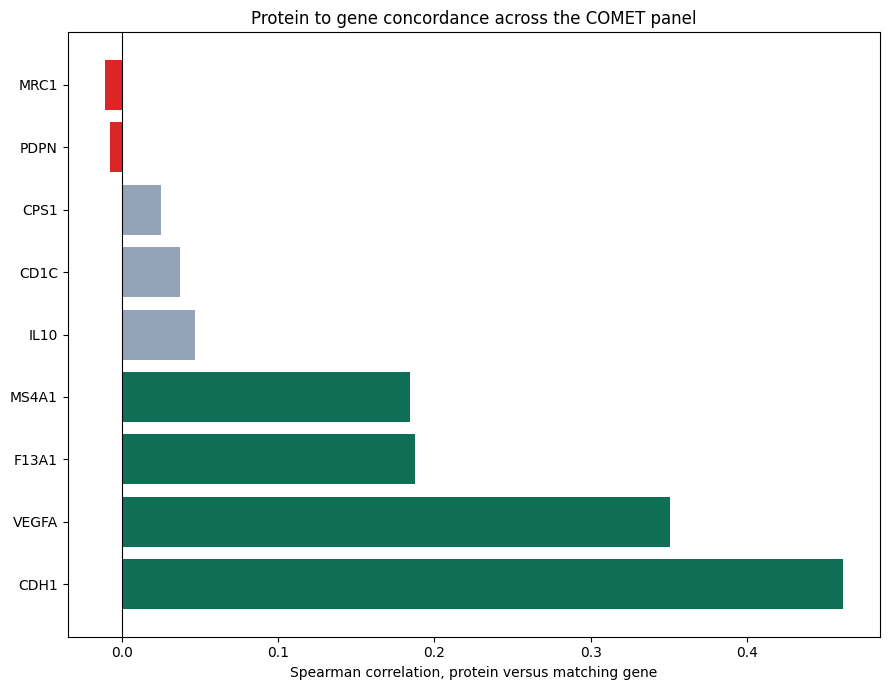

Saved slide_concordance_bar_chart.png


In [5]:
fig, ax = plt.subplots(figsize=(9, 7))
plot_df = results_df_sorted.dropna(subset=["spearman_r"])
colors = ["#0F6E56" if r > 0.1 else "#DC2626" if r < 0 else "#94A3B8" for r in plot_df["spearman_r"]]
ax.barh(plot_df["gene"], plot_df["spearman_r"], color=colors)
ax.set_xlabel("Spearman correlation, protein versus matching gene")
ax.set_title("Protein to gene concordance across the COMET panel")
ax.axvline(0, color="black", linewidth=0.8)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "slide_concordance_bar_chart.png", dpi=200, facecolor="white")
plt.show()

print("Saved slide_concordance_bar_chart.png")


## HepPar1 and CPS1, a closer look

CPS1 is a well documented case in hepatocellular carcinoma research. Tumor hepatocytes are known to silence CPS1 gene expression through promoter methylation, even while often retaining the HepPar1 protein signature that marks their hepatocyte lineage. In other words, HepPar1 protein reflects what a cell is, its hepatocyte identity, while CPS1 transcript reflects what a cell is currently doing, actively running its normal metabolic program or not. This connects directly to what we saw in the last episode, tumor tissue broadly silencing normal liver metabolic genes.


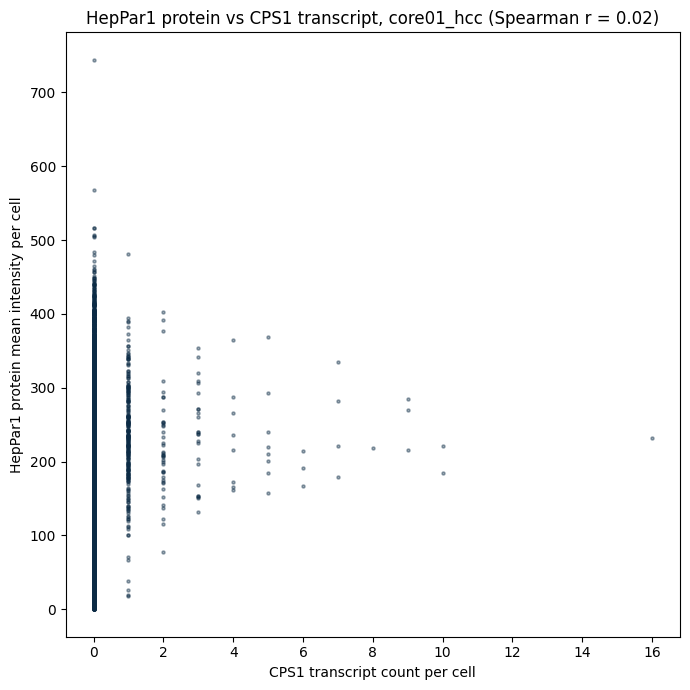

Saved slide_heppar1_vs_cps1.png


In [6]:
fig, ax = plt.subplots(figsize=(7, 7))
ax.scatter(df["CPS1"], df["HepPar1 - TRITC_mean"], s=5, alpha=0.4, color="#0C2B45")
ax.set_xlabel("CPS1 transcript count per cell")
ax.set_ylabel("HepPar1 protein mean intensity per cell")
r_val = results_df.loc[results_df["gene"] == "CPS1", "spearman_r"].values[0]
ax.set_title(f"HepPar1 protein vs CPS1 transcript, core01_hcc (Spearman r = {r_val:.2f})")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "slide_heppar1_vs_cps1.png", dpi=200, facecolor="white")
plt.show()

print("Saved slide_heppar1_vs_cps1.png")


## Summary

A low correlation between a protein and its matching gene is not automatically a technical failure. Sometimes, as with HepPar1 and CPS1, it is the most biologically informative result in the entire comparison, revealing a real distinction between cell identity and current cell activity that neither modality could show on its own. Across the panel as a whole, agreement genuinely varies by marker, and that variation itself is worth reporting honestly rather than only showcasing the pairs that happen to agree.

Next episode, we move from single cell properties to cell to cell relationships, asking whether specific pairs of cell types sit closer together than chance would predict, not just whether each type clusters with itself.
